In [1]:
# ==================================================
# 01. CONFIGURACIÓN DEL ENTORNO DE EVALUACIÓN
# ==================================================

from google.colab import drive
drive.mount("/content/drive")

import sys
import json
import csv
import torch
import pandas as pd
import sentencepiece as spm

from pathlib import Path

BASE_DIR = Path(
    "/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado"
)

DATA_DIR = BASE_DIR / "datasets" / "raw"
MODEL_DIR = BASE_DIR / "modelo"
TOKENIZER_DIR = BASE_DIR / "tokenizador"
CHECKPOINT_DIR = BASE_DIR / "checkpoints"
RESULTS_DIR = BASE_DIR / "resultados"

TEST_PATH = DATA_DIR / "test.tsv"
BEST_CHECKPOINT = CHECKPOINT_DIR / "mejor_modelo.pth"
TOKENIZER_PATH = TOKENIZER_DIR / "tokenizer.model"

# Verificar archivos
archivos = [
    TEST_PATH,
    MODEL_DIR / "transformer_model.py",
    BEST_CHECKPOINT,
    TOKENIZER_PATH
]

for archivo in archivos:
    assert archivo.exists(), f"No encontrado: {archivo}"

# Dispositivo
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

assert DEVICE.type == "cuda", "Activa GPU en Colab para evaluar más rápido."

# Cargar checkpoint del mejor modelo
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

MODEL_CONFIG = checkpoint["model_config"]
TRAIN_CONFIG = checkpoint["train_config"]

# Cargar tokenizador
sp = spm.SentencePieceProcessor(
    model_file=str(TOKENIZER_PATH)
)

# Importar arquitectura
if str(MODEL_DIR) not in sys.path:
    sys.path.insert(0, str(MODEL_DIR))

from transformer_model import TranslationTransformer

print("=" * 60)
print("ENTORNO DE EVALUACIÓN")
print("=" * 60)
print("GPU:", torch.cuda.get_device_name(0))
print("Mejor modelo - época:", checkpoint["epoch"] + 1)
print("Best Validation Loss:", checkpoint["best_val_loss"])
print("Vocabulario:", sp.vocab_size())
print("Test disponible:", TEST_PATH.exists())
print("\nEntorno preparado correctamente.")

Mounted at /content/drive
ENTORNO DE EVALUACIÓN
GPU: Tesla T4
Mejor modelo - época: 15
Best Validation Loss: 2.0290010670697933
Vocabulario: 16000
Test disponible: True

Entorno preparado correctamente.


In [2]:
# ==================================================
# 02. CARGA DEL MEJOR MODELO Y DATASET DE TEST
# ==================================================

# 1. Reconstruir arquitectura
model = TranslationTransformer(
    MODEL_CONFIG
).to(DEVICE)

# 2. Cargar pesos del mejor modelo
model.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

model.eval()

# 3. Verificar número de parámetros
total_params = sum(
    p.numel() for p in model.parameters()
)

assert total_params == 19_677_824

# 4. Cargar test.tsv
test_df = pd.read_csv(
    TEST_PATH,
    sep="\t",
    header=None,
    names=["en", "es", "id_original"],
    dtype=str,
    keep_default_na=False,
    quoting=csv.QUOTE_NONE
)

# 5. Verificaciones
assert len(test_df) == 44_004
assert test_df["en"].isna().sum() == 0
assert test_df["es"].isna().sum() == 0

print("=" * 60)
print("MODELO Y TEST CARGADOS")
print("=" * 60)

print("Parámetros:", f"{total_params:,}")
print("Modelo:", "mejor_modelo.pth")
print("Época:", checkpoint["epoch"] + 1)
print("Modo evaluación:", not model.training)

print("\nDataset test:")
print("Ejemplos:", f"{len(test_df):,}")
print("Nulos EN:", test_df["en"].isna().sum())
print("Nulos ES:", test_df["es"].isna().sum())

print("\nPrimeros 3 ejemplos:")
for i in range(3):
    print(f"\n{i+1}. EN:", test_df.iloc[i]["en"])
    print("   ES:", test_df.iloc[i]["es"])

print("\nCelda 2 completada correctamente.")

MODELO Y TEST CARGADOS
Parámetros: 19,677,824
Modelo: mejor_modelo.pth
Época: 15
Modo evaluación: True

Dataset test:
Ejemplos: 44,004
Nulos EN: 0
Nulos ES: 0

Primeros 3 ejemplos:

1. EN: How'd you know that?
   ES: El 3406.

2. EN: And it was like the biggest shock of my life.
   ES: Y fue como el shock más grande de mi vida.

3. EN: I'll give you some milk.
   ES: Te daré leche.

Celda 2 completada correctamente.


In [3]:
# ==================================================
# 03. INFERENCIA AUTOREGRESIVA - GREEDY DECODING
# ==================================================

import torch

BOS_ID = sp.bos_id()
EOS_ID = sp.eos_id()
PAD_ID = sp.pad_id()

MAX_LENGTH = MODEL_CONFIG["max_length"]


def preparar_entrada(texto):
    """
    Tokeniza una oración en inglés agregando BOS y EOS.
    """

    tokens = sp.encode(
        texto,
        out_type=int
    )

    tokens = tokens[:MAX_LENGTH - 2]

    tokens = (
        [BOS_ID]
        + tokens
        + [EOS_ID]
    )

    return torch.tensor(
        tokens,
        dtype=torch.long,
        device=DEVICE
    ).unsqueeze(0)


@torch.no_grad()
def traducir_greedy(texto, max_length=MAX_LENGTH):
    """
    Traduce inglés -> español de manera autoregresiva
    usando greedy decoding.
    """

    model.eval()

    src = preparar_entrada(texto)

    # El decoder comienza únicamente con BOS
    generated = torch.tensor(
        [[BOS_ID]],
        dtype=torch.long,
        device=DEVICE
    )

    for _ in range(max_length - 1):

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=DEVICE.type == "cuda"
        ):

            logits = model(
                src,
                generated
            )

        # Predicción del siguiente token
        next_token = torch.argmax(
            logits[:, -1, :],
            dim=-1
        )

        token_id = next_token.item()

        generated = torch.cat(
            [
                generated,
                next_token.unsqueeze(1)
            ],
            dim=1
        )

        # Finalizar cuando aparece EOS
        if token_id == EOS_ID:
            break

    # Pasar a CPU
    tokens_generados = (
        generated.squeeze(0)
        .detach()
        .cpu()
        .tolist()
    )

    # Eliminar BOS, EOS y PAD
    tokens_limpios = [
        token
        for token in tokens_generados
        if token not in {BOS_ID, EOS_ID, PAD_ID}
    ]

    traduccion = sp.decode(tokens_limpios)

    return traduccion.strip()


print("=" * 60)
print("FUNCIÓN DE TRADUCCIÓN PREPARADA")
print("=" * 60)

print("Método: Greedy autoregresivo")
print("BOS:", BOS_ID)
print("EOS:", EOS_ID)
print("PAD:", PAD_ID)
print("Longitud máxima:", MAX_LENGTH)
print("Modelo en evaluación:", not model.training)

print("\nCelda 3 completada correctamente.")

FUNCIÓN DE TRADUCCIÓN PREPARADA
Método: Greedy autoregresivo
BOS: 2
EOS: 3
PAD: 0
Longitud máxima: 80
Modelo en evaluación: True

Celda 3 completada correctamente.


In [4]:
# ==================================================
# 04. PRUEBA RÁPIDA DE INFERENCIA
# ==================================================

frases_prueba = [
    "Hello, how are you?",
    "I love this movie.",
    "Where are you going?",
    "I'll give you some milk.",
    "And it was like the biggest shock of my life."
]

print("=" * 70)
print("PRUEBA RÁPIDA DE TRADUCCIÓN")
print("=" * 70)

for i, frase in enumerate(frases_prueba, start=1):
    traduccion = traducir_greedy(frase)

    print(f"\n{i}. EN: {frase}")
    print(f"   ES: {traduccion}")

print("\nPrueba completada.")

PRUEBA RÁPIDA DE TRADUCCIÓN

1. EN: Hello, how are you?
   ES: Hola, ¿cómo estás?

2. EN: I love this movie.
   ES: Me encanta esta película.

3. EN: Where are you going?
   ES: ¿A dónde vas?

4. EN: I'll give you some milk.
   ES: Te daré leche.

5. EN: And it was like the biggest shock of my life.
   ES: Y fue como el mayor shock de mi vida.

Prueba completada.


In [5]:
# ==================================================
# 05. EVALUACIÓN SOBRE 100 EJEMPLOS DEL TEST
# ==================================================

import time
import pandas as pd
from tqdm.auto import tqdm

N_EJEMPLOS = 100
SEED_EVALUACION = 42

# Selección reproducible
muestra_test = test_df.sample(
    n=N_EJEMPLOS,
    random_state=SEED_EVALUACION
).reset_index(drop=True)

resultados = []

inicio = time.perf_counter()

for i, fila in tqdm(
    muestra_test.iterrows(),
    total=N_EJEMPLOS,
    desc="Traduciendo test"
):
    ingles = fila["en"]
    referencia = fila["es"]

    prediccion = traducir_greedy(ingles)

    resultados.append({
        "id_original": fila["id_original"],
        "ingles": ingles,
        "referencia_es": referencia,
        "prediccion_es": prediccion
    })

duracion = time.perf_counter() - inicio

resultados_df = pd.DataFrame(resultados)

# Directorio de evaluación
EVAL_DIR = RESULTS_DIR / "evaluacion"
EVAL_DIR.mkdir(parents=True, exist_ok=True)

RESULTADOS_100_PATH = EVAL_DIR / "evaluacion_100_ejemplos.csv"

resultados_df.to_csv(
    RESULTADOS_100_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("EVALUACIÓN DE 100 EJEMPLOS COMPLETADA")
print("=" * 70)

print("Ejemplos:", len(resultados_df))
print(f"Duración: {duracion:.2f} segundos")
print(f"Promedio por frase: {duracion / len(resultados_df):.3f} s")

print("\nArchivo guardado:")
print(RESULTADOS_100_PATH)

print("\nPrimeros 5 resultados:")

for i in range(5):
    fila = resultados_df.iloc[i]

    print(f"\n{i+1}. EN:  {fila['ingles']}")
    print(f"   REF: {fila['referencia_es']}")
    print(f"   MOD: {fila['prediccion_es']}")

print("\nCelda 5 completada correctamente.")

Traduciendo test:   0%|          | 0/100 [00:00<?, ?it/s]

EVALUACIÓN DE 100 EJEMPLOS COMPLETADA
Ejemplos: 100
Duración: 11.82 segundos
Promedio por frase: 0.118 s

Archivo guardado:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/evaluacion_100_ejemplos.csv

Primeros 5 resultados:

1. EN:  And Gunderson wants to know when he can get his ribs and beer a-and the hustler.
   REF: Y Gunderson quiere saber cuando puede tener sus costillas y cerveza y... la prostituta.
   MOD: Y Gustler quiere saber cuando puede conseguir una cerveza y la cerveza.

2. EN:  I landed at the Office of the Director.
   REF: Llegué a la oficina del Director.
   MOD: Yo aterrizé en el Ministerio del Director.

3. EN:  I saw what he described exactly how he said it.
   REF: Vi lo que describió. Es exactamente lo que dijo.
   MOD: He descrito exactamente lo que dijo.

4. EN:  Who the hell are you?
   REF: ¿Quién diablos eres tu?
   MOD: ¿Quién demonios eres?

5. EN:  That is a world of bad luck you do not want a part of.
   REF: Es un m

In [6]:
!pip -q install sacrebleu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 4.0 MB/s eta 0:00:00


In [7]:
# ==================================================
# 06. MÉTRICAS FORMALES DE EVALUACIÓN
# ==================================================

import json
import sacrebleu

predicciones = resultados_df["prediccion_es"].tolist()
referencias = resultados_df["referencia_es"].tolist()

refs = [referencias]

# BLEU
bleu = sacrebleu.corpus_bleu(
    predicciones,
    refs
)

# chrF
chrf = sacrebleu.corpus_chrf(
    predicciones,
    refs
)

# TER
ter = sacrebleu.corpus_ter(
    predicciones,
    refs
)

metricas = {
    "numero_ejemplos": len(predicciones),
    "sacrebleu": float(bleu.score),
    "chrf": float(chrf.score),
    "ter": float(ter.score),
    "brevity_penalty": float(bleu.bp),
    "system_length": int(bleu.sys_len),
    "reference_length": int(bleu.ref_len)
}

METRICAS_PATH = EVAL_DIR / "metricas_100_ejemplos.json"

with open(METRICAS_PATH, "w", encoding="utf-8") as f:
    json.dump(
        metricas,
        f,
        indent=4,
        ensure_ascii=False
    )

print("=" * 70)
print("MÉTRICAS FORMALES DE TRADUCCIÓN")
print("=" * 70)

print(f"Ejemplos evaluados: {len(predicciones)}")

print("\n--- SacreBLEU ---")
print(f"BLEU:              {bleu.score:.4f}")
print(f"Brevity Penalty:   {bleu.bp:.4f}")
print(f"Longitud sistema:  {bleu.sys_len}")
print(f"Longitud referencia: {bleu.ref_len}")

print("\n--- chrF ---")
print(f"chrF: {chrf.score:.4f}")

print("\n--- TER ---")
print(f"TER:  {ter.score:.4f}")

print("\nArchivo:")
print(METRICAS_PATH)

print("\nCelda 6 completada correctamente.")

MÉTRICAS FORMALES DE TRADUCCIÓN
Ejemplos evaluados: 100

--- SacreBLEU ---
BLEU:              23.9699
Brevity Penalty:   0.9987
Longitud sistema:  782
Longitud referencia: 783

--- chrF ---
chrF: 45.6664

--- TER ---
TER:  72.2496

Archivo:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/metricas_100_ejemplos.json

Celda 6 completada correctamente.


In [8]:
# ==================================================
# 07. MÉTRICAS POR EJEMPLO Y ANÁLISIS DE CASOS
# ==================================================

import sacrebleu
import pandas as pd

bleu_metric = sacrebleu.metrics.BLEU(
    effective_order=True
)

chrf_metric = sacrebleu.metrics.CHRF()

bleu_individual = []
chrf_individual = []

for _, fila in resultados_df.iterrows():

    pred = fila["prediccion_es"]
    ref = fila["referencia_es"]

    bleu_i = bleu_metric.sentence_score(
        pred,
        [ref]
    ).score

    chrf_i = chrf_metric.sentence_score(
        pred,
        [ref]
    ).score

    bleu_individual.append(bleu_i)
    chrf_individual.append(chrf_i)

resultados_df["bleu_individual"] = bleu_individual
resultados_df["chrf_individual"] = chrf_individual

# Ordenar por chrF
ranking = resultados_df.sort_values(
    "chrf_individual",
    ascending=False
).reset_index(drop=True)

# Guardar versión enriquecida
RESULTADOS_METRICAS_PATH = (
    EVAL_DIR / "evaluacion_100_con_metricas.csv"
)

resultados_df.to_csv(
    RESULTADOS_METRICAS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("ANÁLISIS INDIVIDUAL DE TRADUCCIONES")
print("=" * 70)

print("\n5 MEJORES TRADUCCIONES\n")

for i in range(5):

    fila = ranking.iloc[i]

    print(f"{i+1}. EN:  {fila['ingles']}")
    print(f"   REF: {fila['referencia_es']}")
    print(f"   MOD: {fila['prediccion_es']}")
    print(f"   BLEU: {fila['bleu_individual']:.2f}")
    print(f"   chrF: {fila['chrf_individual']:.2f}")
    print()

print("-" * 70)

print("\n5 TRADUCCIONES CON MENOR chrF\n")

peores = ranking.tail(5).iloc[::-1]

for i, (_, fila) in enumerate(
    peores.iterrows(),
    start=1
):

    print(f"{i}. EN:  {fila['ingles']}")
    print(f"   REF: {fila['referencia_es']}")
    print(f"   MOD: {fila['prediccion_es']}")
    print(f"   BLEU: {fila['bleu_individual']:.2f}")
    print(f"   chrF: {fila['chrf_individual']:.2f}")
    print()

print("Archivo guardado:")
print(RESULTADOS_METRICAS_PATH)

print("\nCelda 7 completada correctamente.")

ANÁLISIS INDIVIDUAL DE TRADUCCIONES

5 MEJORES TRADUCCIONES

1. EN:  My face!
   REF: ¡Mi cara!
   MOD: ¡Mi cara!
   BLEU: 100.00
   chrF: 100.00

2. EN:  Dad, are you okay?
   REF: Papá, ¿estás bien?
   MOD: Papá, ¿estás bien?
   BLEU: 100.00
   chrF: 100.00

3. EN:  They're kids.
   REF: Son niños .
   MOD: Son niños.
   BLEU: 100.00
   chrF: 100.00

4. EN:  Oh. Really? - Yeah.
   REF: ¿En serio?
   MOD: ¿En serio?
   BLEU: 100.00
   chrF: 100.00

5. EN:  I need to know where she is.
   REF: Necesito saber dónde está.
   MOD: Necesito saber dónde está.
   BLEU: 100.00
   chrF: 100.00

----------------------------------------------------------------------

5 TRADUCCIONES CON MENOR chrF

1. EN:  Hurry!
   REF: Rapido!
   MOD: ¡Apresúrate!
   BLEU: 50.00
   chrF: 6.25

2. EN:  He'll be out soon.
   REF: Ya va a llegar.
   MOD: Pronto saldrá.
   BLEU: 14.13
   chrF: 6.95

3. EN:  I'm O. A Fulltime Killer.
   REF: Soy O. Un asesino de tiempo completo.
   MOD: Soy A. Killer Full.
   BLEU: 

In [9]:
# ==================================================
# 08. DISTRIBUCIÓN DE RESULTADOS POR chrF
# ==================================================

import pandas as pd

def clasificar_chrf(score):
    if score >= 80:
        return "Muy alta similitud"
    elif score >= 60:
        return "Alta similitud"
    elif score >= 40:
        return "Similitud media"
    elif score >= 20:
        return "Baja similitud"
    else:
        return "Muy baja similitud"

resultados_df["categoria_chrf"] = (
    resultados_df["chrf_individual"]
    .apply(clasificar_chrf)
)

orden = [
    "Muy alta similitud",
    "Alta similitud",
    "Similitud media",
    "Baja similitud",
    "Muy baja similitud"
]

distribucion = (
    resultados_df["categoria_chrf"]
    .value_counts()
    .reindex(orden, fill_value=0)
)

porcentajes = (
    distribucion / len(resultados_df) * 100
).round(2)

resumen_calidad = pd.DataFrame({
    "cantidad": distribucion,
    "porcentaje": porcentajes
})

print("=" * 70)
print("DISTRIBUCIÓN DE LOS 100 EJEMPLOS SEGÚN chrF")
print("=" * 70)

print(resumen_calidad)

print("\nExact matches:")

exactos = (
    (resultados_df["bleu_individual"] == 100)
    & (resultados_df["chrf_individual"] == 100)
).sum()

print("Traducciones idénticas a la referencia:", exactos)
print(
    "Porcentaje:",
    f"{exactos / len(resultados_df) * 100:.2f}%"
)

# Guardar resumen
RESUMEN_PATH = EVAL_DIR / "distribucion_calidad_100.csv"

resumen_calidad.to_csv(
    RESUMEN_PATH,
    encoding="utf-8-sig"
)

print("\nArchivo guardado:")
print(RESUMEN_PATH)

print("\nCelda 8 completada correctamente.")

DISTRIBUCIÓN DE LOS 100 EJEMPLOS SEGÚN chrF
                    cantidad  porcentaje
categoria_chrf                          
Muy alta similitud        15        15.0
Alta similitud            11        11.0
Similitud media           31        31.0
Baja similitud            27        27.0
Muy baja similitud        16        16.0

Exact matches:
Traducciones idénticas a la referencia: 0
Porcentaje: 0.00%

Archivo guardado:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/distribucion_calidad_100.csv

Celda 8 completada correctamente.


In [10]:
# ==================================================
# 09. CORRECCIÓN DE EXACT MATCHES
# ==================================================

import numpy as np

# 1. Coincidencias métricas perfectas
metricamente_perfectas = (
    np.isclose(
        resultados_df["bleu_individual"],
        100.0,
        atol=1e-6
    )
    &
    np.isclose(
        resultados_df["chrf_individual"],
        100.0,
        atol=1e-6
    )
)

n_metricas_100 = metricamente_perfectas.sum()

# 2. Coincidencia textual exacta
coincidencia_textual = (
    resultados_df["referencia_es"].str.strip()
    ==
    resultados_df["prediccion_es"].str.strip()
)

n_textuales = coincidencia_textual.sum()

print("=" * 70)
print("VERIFICACIÓN DE COINCIDENCIAS PERFECTAS")
print("=" * 70)

print(
    "BLEU≈100 y chrF≈100:",
    n_metricas_100,
    f"({n_metricas_100 / len(resultados_df) * 100:.2f}%)"
)

print(
    "Texto exactamente igual:",
    n_textuales,
    f"({n_textuales / len(resultados_df) * 100:.2f}%)"
)

print("\nCasos con métricas perfectas:\n")

perfectas = resultados_df[metricamente_perfectas]

for i, (_, fila) in enumerate(
    perfectas.iterrows(),
    start=1
):
    print(f"{i}. EN:  {fila['ingles']}")
    print(f"   REF: {fila['referencia_es']}")
    print(f"   MOD: {fila['prediccion_es']}")
    print()

VERIFICACIÓN DE COINCIDENCIAS PERFECTAS
BLEU≈100 y chrF≈100: 11 (11.00%)
Texto exactamente igual: 10 (10.00%)

Casos con métricas perfectas:

1. EN:  Oh. Really? - Yeah.
   REF: ¿En serio?
   MOD: ¿En serio?

2. EN:  A mouth?
   REF: ¿Una boca?
   MOD: ¿Una boca?

3. EN:  Dad, are you okay?
   REF: Papá, ¿estás bien?
   MOD: Papá, ¿estás bien?

4. EN:  I need to know where she is.
   REF: Necesito saber dónde está.
   MOD: Necesito saber dónde está.

5. EN:  They're kids.
   REF: Son niños .
   MOD: Son niños.

6. EN:  My face!
   REF: ¡Mi cara!
   MOD: ¡Mi cara!

7. EN:  Where the hell were you?
   REF: ¿Dónde diablos estabas?
   MOD: ¿Dónde diablos estabas?

8. EN:  Ronny, talk to me.
   REF: Ronny, háblame.
   MOD: Ronny, háblame.

9. EN:  I want them both.
   REF: Los quiero a ambos.
   MOD: Los quiero a ambos.

10. EN:  I don't know if I can help you.
   REF: No sé si puedo ayudarte.
   MOD: No sé si puedo ayudarte.

11. EN:  Gay people get married.
   REF: Los gay se casan.
   MO

In [11]:
# ==================================================
# 10. PREPARACIÓN DEL ANÁLISIS CUALITATIVO
# ==================================================

analisis_df = resultados_df.copy()

# Ordenamos de menor a mayor similitud para revisar
# primero los casos potencialmente problemáticos.
analisis_df = analisis_df.sort_values(
    "chrf_individual",
    ascending=True
).reset_index(drop=True)

# Columnas para análisis manual
analisis_df["clasificacion_manual"] = ""
analisis_df["tipo_error"] = ""
analisis_df["comentario"] = ""

COLUMNAS = [
    "id_original",
    "ingles",
    "referencia_es",
    "prediccion_es",
    "bleu_individual",
    "chrf_individual",
    "categoria_chrf",
    "clasificacion_manual",
    "tipo_error",
    "comentario"
]

analisis_df = analisis_df[COLUMNAS]

ANALISIS_PATH = (
    EVAL_DIR / "analisis_cualitativo_100_ejemplos.csv"
)

analisis_df.to_csv(
    ANALISIS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("ARCHIVO PARA ANÁLISIS CUALITATIVO")
print("=" * 70)

print("Ejemplos:", len(analisis_df))
print("Archivo:", ANALISIS_PATH)

print("\n15 CASOS CON MENOR chrF:\n")

for i in range(15):
    fila = analisis_df.iloc[i]

    print(f"{i+1}. EN:  {fila['ingles']}")
    print(f"   REF: {fila['referencia_es']}")
    print(f"   MOD: {fila['prediccion_es']}")
    print(
        f"   BLEU={fila['bleu_individual']:.2f} | "
        f"chrF={fila['chrf_individual']:.2f}"
    )
    print()

print("Celda 10 completada correctamente.")

ARCHIVO PARA ANÁLISIS CUALITATIVO
Ejemplos: 100
Archivo: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/analisis_cualitativo_100_ejemplos.csv

15 CASOS CON MENOR chrF:

1. EN:  Hurry!
   REF: Rapido!
   MOD: ¡Apresúrate!
   BLEU=50.00 | chrF=6.25

2. EN:  He'll be out soon.
   REF: Ya va a llegar.
   MOD: Pronto saldrá.
   BLEU=14.13 | chrF=6.95

3. EN:  I'm O. A Fulltime Killer.
   REF: Soy O. Un asesino de tiempo completo.
   MOD: Soy A. Killer Full.
   BLEU=6.48 | chrF=7.26

4. EN:  Rossi's behind all this.
   REF: Ahora yo.
   MOD: Rossi está detrás de todo esto.
   BLEU=6.57 | chrF=7.32

5. EN:  Hang in there. Oh...
   REF: Aguanta.
   MOD: Espera... ahí.
   BLEU=8.12 | chrF=7.64

6. EN:  All of you!
   REF: ¡Deténganse!
   MOD: ¡Todos ustedes!
   BLEU=27.52 | chrF=8.06

7. EN:  54º 05' 20" North... 12º 08' 24" East.
   REF: anotar estas coordenadas: 54 ° 05' 20" Norte... 12o 08' 24" Oeste.
   MOD: 01545... 84, 015... 8... 8 de la 25 de la mad

In [12]:
# ==================================================
# 11. REGISTRAR CLASIFICACIÓN CUALITATIVA
# ==================================================

clasificaciones = [
    ("Correcta / equivalente", "Paráfrasis válida",
     "Traducción válida; la referencia usa otra formulación."),

    ("Correcta / equivalente", "Paráfrasis válida",
     "Traducción natural; la referencia expresa una variante contextual."),

    ("Incorrecta", "Error léxico/semántico",
     "Mantiene fragmentos en inglés y altera el sentido."),

    ("Correcta", "Referencia ruidosa",
     "La predicción corresponde al inglés; la referencia parece desalineada."),

    ("Parcialmente correcta", "Error idiomático",
     "Interpretación demasiado literal de una expresión idiomática."),

    ("Correcta literal", "Referencia contextual/ruidosa",
     "La predicción traduce el texto fuente; la referencia requiere contexto externo."),

    ("Incorrecta", "Números/formato",
     "Fallo grave al reproducir coordenadas, números y orientación cardinal."),

    ("Correcta", "Referencia ruidosa",
     "La predicción es adecuada; la referencia no corresponde bien al texto fuente."),

    ("Parcialmente correcta", "Error semántico/pragmático",
     "Cambia la relación entre hablantes y mezcla formas de tratamiento."),

    ("Incorrecta", "Error gramatical/semántico",
     "Confunde objeto plural con segunda persona singular."),

    ("Incorrecta", "Error léxico",
     "No reconoce correctamente la expresión 'full steam ahead'."),

    ("Incorrecta", "Error léxico",
     "Confunde 'rubbish' con una palabra semánticamente no relacionada."),

    ("Correcta / natural", "Paráfrasis válida",
     "La traducción generada es natural y conserva la intención."),

    ("Incorrecta", "Repetición + omisión",
     "Presenta repetición y pérdida de información importante."),

    ("Incorrecta", "Error idiomático",
     "Traduce 'deal' literalmente en lugar de interpretar su sentido contextual.")
]

for i, (clasificacion, tipo, comentario) in enumerate(clasificaciones):
    analisis_df.loc[i, "clasificacion_manual"] = clasificacion
    analisis_df.loc[i, "tipo_error"] = tipo
    analisis_df.loc[i, "comentario"] = comentario

analisis_df.to_csv(
    ANALISIS_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("=" * 70)
print("CLASIFICACIÓN CUALITATIVA GUARDADA")
print("=" * 70)

print("Casos clasificados:", 15)
print("Archivo:", ANALISIS_PATH)

print("\nCelda 11 completada correctamente.")

CLASIFICACIÓN CUALITATIVA GUARDADA
Casos clasificados: 15
Archivo: /content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/analisis_cualitativo_100_ejemplos.csv

Celda 11 completada correctamente.


RESUMEN DE TIPOS DE ERROR / CASOS
                   tipo_error  cantidad  porcentaje
            Paráfrasis válida         3       20.00
           Referencia ruidosa         2       13.33
                 Error léxico         2       13.33
             Error idiomático         2       13.33
       Error léxico/semántico         1        6.67
Referencia contextual/ruidosa         1        6.67
              Números/formato         1        6.67
   Error semántico/pragmático         1        6.67
   Error gramatical/semántico         1        6.67
         Repetición + omisión         1        6.67


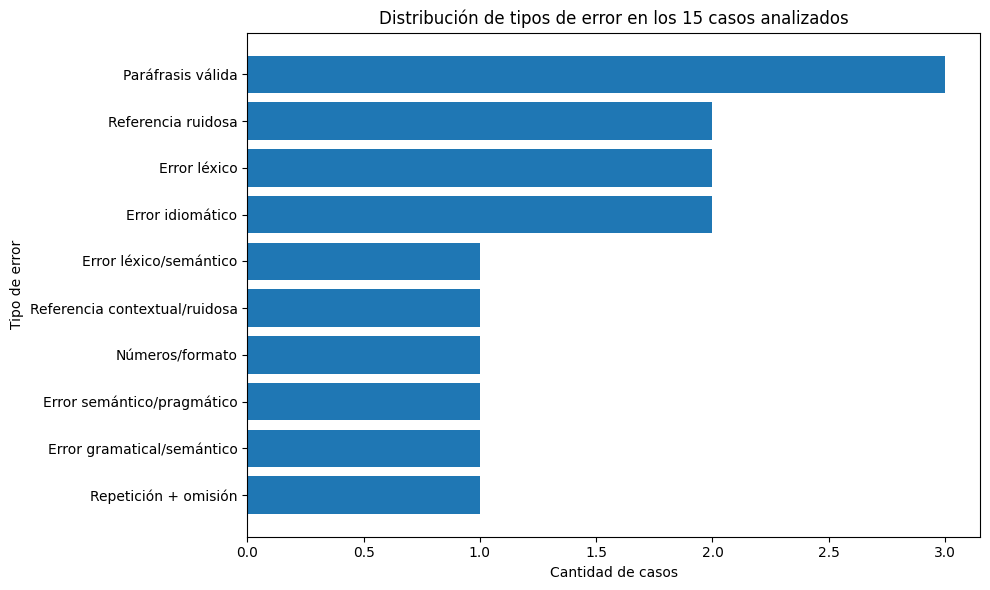


Archivos guardados:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/resumen_tipos_error_15_casos.csv
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/grafico_tipos_error_15_casos.png

Celda 12 completada correctamente.


In [13]:
# ==================================================
# 12. RESUMEN DE TIPOS DE ERROR
# ==================================================

import pandas as pd
import matplotlib.pyplot as plt

# Tomar solo los casos ya clasificados
clasificados = analisis_df[
    analisis_df["clasificacion_manual"].str.strip() != ""
].copy()

# Conteo por tipo de error
resumen_errores = (
    clasificados["tipo_error"]
    .value_counts()
    .reset_index()
)

resumen_errores.columns = [
    "tipo_error",
    "cantidad"
]

resumen_errores["porcentaje"] = (
    resumen_errores["cantidad"]
    / len(clasificados)
    * 100
).round(2)

print("=" * 70)
print("RESUMEN DE TIPOS DE ERROR / CASOS")
print("=" * 70)

print(resumen_errores.to_string(index=False))

# Guardar tabla
RESUMEN_ERRORES_PATH = (
    EVAL_DIR / "resumen_tipos_error_15_casos.csv"
)

resumen_errores.to_csv(
    RESUMEN_ERRORES_PATH,
    index=False,
    encoding="utf-8-sig"
)

# ==================================================
# GRÁFICO
# ==================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    resumen_errores["tipo_error"],
    resumen_errores["cantidad"]
)

ax.set(
    title="Distribución de tipos de error en los 15 casos analizados",
    xlabel="Cantidad de casos",
    ylabel="Tipo de error"
)

ax.invert_yaxis()

fig.tight_layout()

GRAFICO_ERRORES_PATH = (
    EVAL_DIR / "grafico_tipos_error_15_casos.png"
)

fig.savefig(
    GRAFICO_ERRORES_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

print("\nArchivos guardados:")
print(RESUMEN_ERRORES_PATH)
print(GRAFICO_ERRORES_PATH)

print("\nCelda 12 completada correctamente.")

In [14]:
# ==================================================
# 13. RESUMEN FINAL DE EVALUACIÓN
# ==================================================

import pandas as pd

# Métricas globales
resumen_final = pd.DataFrame({
    "Métrica": [
        "SacreBLEU",
        "chrF",
        "TER",
        "Brevity Penalty",
        "Coincidencia métrica perfecta",
        "Coincidencia textual exacta",
        "Muy alta similitud chrF",
        "Alta similitud chrF",
        "Similitud media chrF",
        "Baja similitud chrF",
        "Muy baja similitud chrF"
    ],
    "Resultado": [
        23.9699,
        45.6664,
        72.2496,
        0.9987,
        "11%",
        "10%",
        "15%",
        "11%",
        "31%",
        "27%",
        "16%"
    ]
})

print("=" * 70)
print("RESUMEN FINAL DE EVALUACIÓN")
print("=" * 70)

print(resumen_final.to_string(index=False))

RESUMEN_FINAL_PATH = EVAL_DIR / "resumen_final_evaluacion.csv"

resumen_final.to_csv(
    RESUMEN_FINAL_PATH,
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivo guardado:")
print(RESUMEN_FINAL_PATH)

print("\nCelda 13 completada correctamente.")

RESUMEN FINAL DE EVALUACIÓN
                      Métrica Resultado
                    SacreBLEU   23.9699
                         chrF   45.6664
                          TER   72.2496
              Brevity Penalty    0.9987
Coincidencia métrica perfecta       11%
  Coincidencia textual exacta       10%
      Muy alta similitud chrF       15%
          Alta similitud chrF       11%
         Similitud media chrF       31%
          Baja similitud chrF       27%
      Muy baja similitud chrF       16%

Archivo guardado:
/content/drive/MyDrive/Proyecto_traductor/traductor_optimizado/resultados/evaluacion/resumen_final_evaluacion.csv

Celda 13 completada correctamente.
